In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Predictive Modeling Project Started Successfully!")

Predictive Modeling Project Started Successfully!


In [2]:
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 2, 5, 6, 9, 3, 7, 8],
    "Attendance": [40, 50, 55, 65, 70, 75, 80, 90, 45, 72, 78, 95, 60, 85, 92],
    "Previous_Marks": [25, 30, 35, 40, 50, 55, 65, 80, 28, 52, 60, 90, 38, 75, 85],
    "Result": [0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1]
}

df = pd.DataFrame(data)

print(df)


    Study_Hours  Attendance  Previous_Marks  Result
0             1          40              25       0
1             2          50              30       0
2             3          55              35       0
3             4          65              40       0
4             5          70              50       1
5             6          75              55       1
6             7          80              65       1
7             8          90              80       1
8             2          45              28       0
9             5          72              52       1
10            6          78              60       1
11            9          95              90       1
12            3          60              38       0
13            7          85              75       1
14            8          92              85       1


In [3]:
# Display first 5 rows
print("First 5 Rows:")
print(df.head())

# Check dataset shape
print("\nDataset Shape:")
print(df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check data information
print("\nDataset Information:")
df.info()

First 5 Rows:
   Study_Hours  Attendance  Previous_Marks  Result
0            1          40              25       0
1            2          50              30       0
2            3          55              35       0
3            4          65              40       0
4            5          70              50       1

Dataset Shape:
(15, 4)

Missing Values:
Study_Hours       0
Attendance        0
Previous_Marks    0
Result            0
dtype: int64

Duplicate Rows:
0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Study_Hours     15 non-null     int64
 1   Attendance      15 non-null     int64
 2   Previous_Marks  15 non-null     int64
 3   Result          15 non-null     int64
dtypes: int64(4)
memory usage: 612.0 bytes


In [4]:
# Input features
X = df[["Study_Hours", "Attendance", "Previous_Marks"]]

# Target variable
y = df["Result"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   Study_Hours  Attendance  Previous_Marks
0            1          40              25
1            2          50              30
2            3          55              35
3            4          65              40
4            5          70              50

Target Variable:
0    0
1    0
2    0
3    0
4    1
Name: Result, dtype: int64


In [5]:
# Input features
X = df[["Study_Hours", "Attendance", "Previous_Marks"]]

# Target variable
y = df["Result"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   Study_Hours  Attendance  Previous_Marks
0            1          40              25
1            2          50              30
2            3          55              35
3            4          65              40
4            5          70              50

Target Variable:
0    0
1    0
2    0
3    0
4    1
Name: Result, dtype: int64


In [6]:
# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data size:", len(X_train))
print("Testing data size:", len(X_test))

print("\nTraining features:")
print(X_train)

print("\nTesting features:")
print(X_test)

Training data size: 12
Testing data size: 3

Training features:
    Study_Hours  Attendance  Previous_Marks
13            7          85              75
5             6          75              55
8             2          45              28
2             3          55              35
1             2          50              30
14            8          92              85
4             5          70              50
7             8          90              80
10            6          78              60
12            3          60              38
3             4          65              40
6             7          80              65

Testing features:
    Study_Hours  Attendance  Previous_Marks
9             5          72              52
11            9          95              90
0             1          40              25


In [7]:
# Create the Decision Tree model
model = DecisionTreeClassifier(random_state=42)

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [8]:
# Predict results using the test data
y_pred = model.predict(X_test)

print("Actual Results:")
print(y_test.values)

print("\nPredicted Results:")
print(y_pred)

Actual Results:
[1 1 0]

Predicted Results:
[1 1 0]


In [9]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 100.0 %


In [10]:
# Display classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



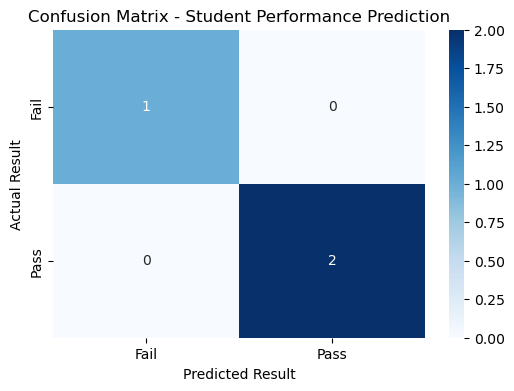

In [11]:
# Import seaborn
import seaborn as sns

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix - Student Performance Prediction")
plt.show()

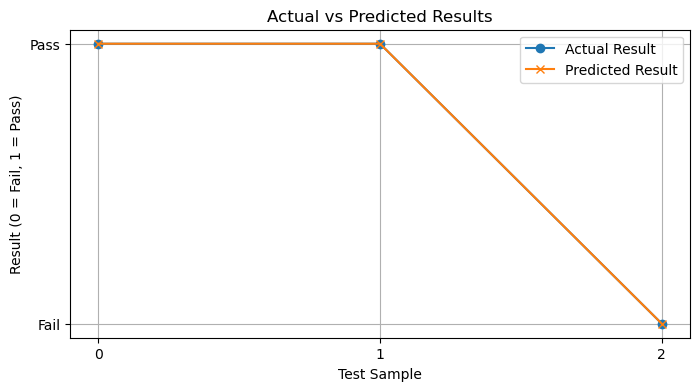

In [12]:
# Compare actual and predicted results
plt.figure(figsize=(8, 4))

plt.plot(
    range(len(y_test)),
    y_test.values,
    marker="o",
    label="Actual Result"
)

plt.plot(
    range(len(y_pred)),
    y_pred,
    marker="x",
    label="Predicted Result"
)

plt.xlabel("Test Sample")
plt.ylabel("Result (0 = Fail, 1 = Pass)")
plt.title("Actual vs Predicted Results")
plt.xticks(range(len(y_test)))
plt.yticks([0, 1], ["Fail", "Pass"])
plt.legend()
plt.grid(True)
plt.show()

In [13]:
%pip install seaborn

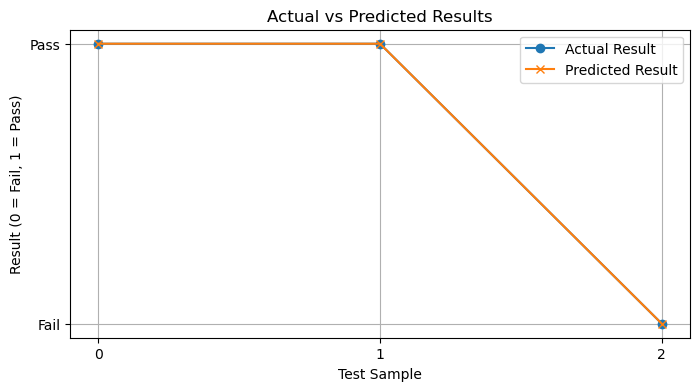

In [14]:
# Compare actual and predicted results
plt.figure(figsize=(8, 4))

plt.plot(
    range(len(y_test)),
    y_test.values,
    marker="o",
    label="Actual Result"
)

plt.plot(
    range(len(y_pred)),
    y_pred,
    marker="x",
    label="Predicted Result"
)

plt.xlabel("Test Sample")
plt.ylabel("Result (0 = Fail, 1 = Pass)")
plt.title("Actual vs Predicted Results")
plt.xticks(range(len(y_test)))
plt.yticks([0, 1], ["Fail", "Pass"])
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# Get student details
study_hours = float(input("Enter study hours per day: "))
attendance = float(input("Enter attendance percentage: "))
previous_marks = float(input("Enter previous marks: "))

# Create input data
new_student = pd.DataFrame({
    "Study_Hours": [study_hours],
    "Attendance": [attendance],
    "Previous_Marks": [previous_marks]
})

# Predict student result
prediction = model.predict(new_student)

# Display prediction
if prediction[0] == 1:
    print("\nPredicted Result: PASS")
else:
    print("\nPredicted Result: FAIL")

Enter study hours per day:  7
Enter attendance percentage:  85
Enter previous marks:  75



Predicted Result: PASS


In [16]:
import joblib

# Save trained model
joblib.dump(model, "student_performance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


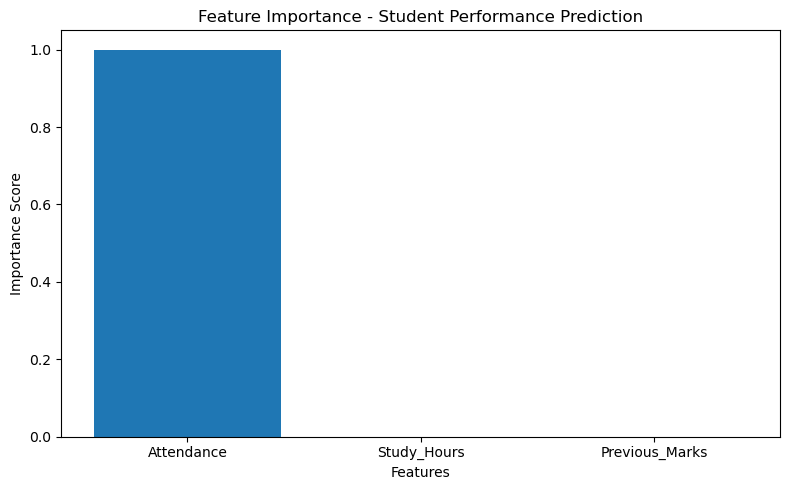

          Feature  Importance
1      Attendance         1.0
0     Study_Hours         0.0
2  Previous_Marks         0.0


In [17]:
# Get feature importance
importance = model.feature_importances_

# Create DataFrame
feature_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

# Sort features by importance
feature_df = feature_df.sort_values(
    by="Importance",
    ascending=False
)

# Plot graph
plt.figure(figsize=(8, 5))

plt.bar(
    feature_df["Feature"],
    feature_df["Importance"]
)

plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.title("Feature Importance - Student Performance Prediction")
plt.tight_layout()
plt.show()

print(feature_df)

In [18]:
%pip install streamlit joblib scikit-learn pandas